# Stern model vs Kalshi: 100-game comparison

Game 6 suggested our model trusts a lead more than the market does. This notebook checks
that on a random sample of games, and asks three questions the quoting rule depends on:

1. **Who is better calibrated, the model or the market?** If the model never beats the
   market, quoting around it loses money.
2. **Where do they disagree?** By quarter and by how lopsided the game is.
3. **What σ is the market acting as if it uses?** Compared with our fitted 19.64.

All data comes from `src/batch_compare.py`, which saves it to
`data/processed/kalshi_vs_model.parquet`. This notebook makes no API calls. To change
the sample, rerun the script (e.g. `uv run python src/batch_compare.py --n 200`).

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

%matplotlib inline
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import batch_compare as bc
import compare_plots as cp  # every chart below

df = bc.load_results()
games = cp.per_game(df)
Q = bc.QUARTER_LABELS

print(f"{len(games)} games, {len(df):,} in-game minutes with a two-sided Kalshi quote")
print(f"{games['date'].min():%Y-%m-%d} to {games['date'].max():%Y-%m-%d}, "
      f"{games.index.str.startswith('004').sum()} playoff games, "
      f"home team won {games['home_won'].mean():.0%}")

100 games, 12,826 in-game minutes with a two-sided Kalshi quote
2025-04-19 to 2026-01-28, 12 playoff games, home team won 62%


**What is in the data.** Games are a random sample (seed 473) from the tuning period
(2025 playoffs to Jan 2026); Feb-Jun 2026 is held out for testing the market maker. Each
row is one Kalshi minute during the game, with the market mid as P(home wins) and the
score and clock as of the most recent play. Two model versions are scored:

- **model, Elo prior**: starts from our Elo pregame probability (the full pipeline).
- **model, tip-off prior**: starts from Kalshi's own price at tip-off, so model and
  market start equal and every later difference is purely in-game updating.

Two kinds of minutes are left out: ones where the order book was one-sided (a bid of 0
or an ask of 1, which happens once a game is decided), and the final buzzer. Both would
flatter the model, which is certain there while the market is not.

Every average below treats **the game as the unit**: each game's minutes are averaged
first, then games are averaged with equal weight, and ±95% intervals are across games.
Minutes within one game are far from independent, so per-minute intervals would be
much too narrow.

## 1. Who predicts the result better?

Log loss and Brier score of each predictor against the final result, on exactly the same
minutes (lower is better). The `- market` rows are the difference from the market:
negative means the model is better.

In [2]:
scores = pd.concat({metric: bc.score_table(df, metric=metric).set_index("value")[["mean", "ci95"]]
                    for metric in bc.LOSSES}, axis=1)
scores.round(4)

log_loss           brier        
                                  mean    ci95    mean    ci95
value                                                         
market                          0.5078  0.0792  0.1714  0.0314
model, Elo prior                0.5276  0.0762  0.1803  0.0301
model, tip-off prior            0.5012  0.0782  0.1694  0.0307
model, Elo prior - market       0.0197  0.0280  0.0089  0.0116
model, tip-off prior - market  -0.0066  0.0080 -0.0020  0.0033

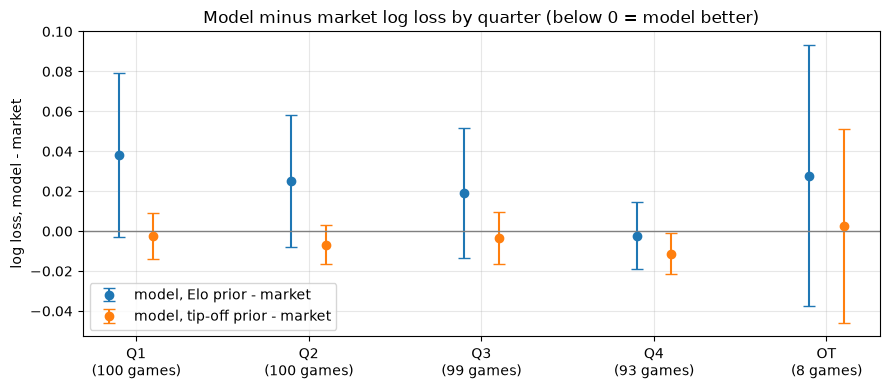

In [3]:
cp.log_loss_by_quarter(df)
plt.show()

## 2. Calibration

When a predictor says 70%, does the home team win about 70% of the time? Minutes are
bucketed by each predictor's own probability; error bars are ±95% across games.

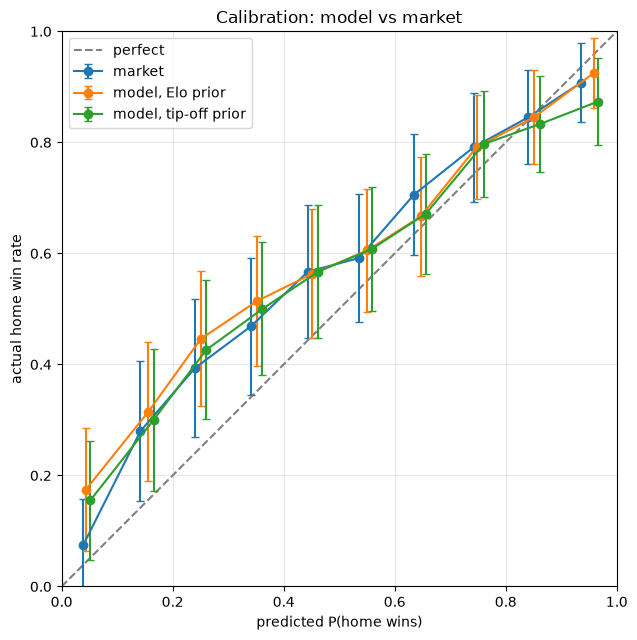

In [4]:
cp.calibration(df)
plt.show()

## 3. Where do they disagree?

**Gap = model - market.** Bucketed by the *market's* probability, not the model's.
Bucketing by the model would show a false tilt: any minute where the model happens to be
high would land in a high bucket, making the model look extreme even if its errors were
pure noise.

If the model trusts leads more than the market, the gap is negative where the market
says the home team is behind (low buckets) and positive where it says ahead.

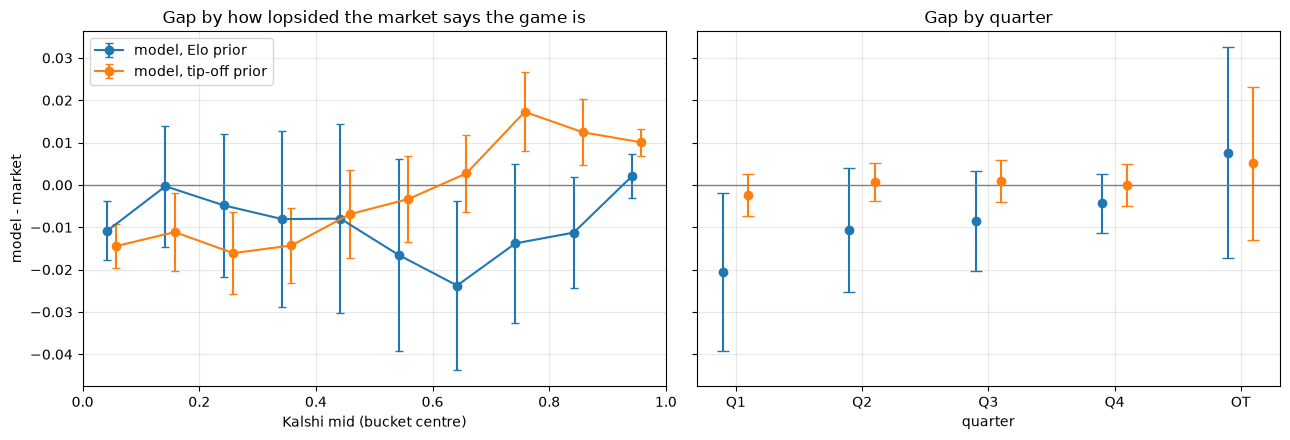

In [5]:
cp.gap(df)
plt.show()

In [6]:
abs_gap = bc.clustered(df, {name: (df[col] - df["mid"]).abs() for name, col in bc.PREDICTORS.items()
                            if name != "market"}, by="quarter")
abs_gap.assign(quarter=abs_gap["group"].map(Q)).pivot(index="quarter", columns="value", values="mean") \
       .reindex(Q.values()).round(3).rename_axis(columns="mean |model - market|")

mean |model - market|,"model, Elo prior","model, tip-off prior"
quarter,,
Q1,0.079,0.026
Q2,0.059,0.023
Q3,0.046,0.024
Q4,0.037,0.030
OT,0.058,0.052


## 4. What σ is the market using?

Using the tip-off prior, so σ is the only thing separating model from market, sweep σ and
measure (left) how far the model sits from the Kalshi mid and (right) how well it
predicts the result. The σ that best matches the market is the market's *implied* σ.

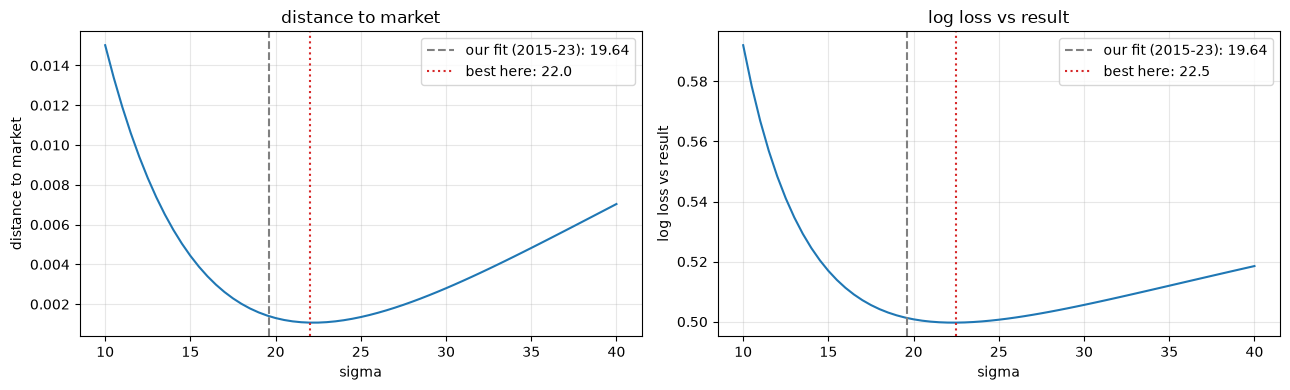

In [7]:
cp.sigma_sweep(df)
plt.show()

In [8]:
by_q = bc.best_sigma(bc.sigma_curve(df, by="quarter"))
by_q.index = by_q.index.map(Q)
by_q.rename_axis(index="quarter", columns="best sigma for")

best sigma for,distance to market,log loss vs result
quarter,,
Q1,26.0,32.0
Q2,22.5,26.0
Q3,21.5,26.5
Q4,22.0,18.5
OT,23.5,17.0


## 5. Elo prior vs Kalshi's tip-off price

How far apart are the two starting points, and which predicts the winner better before
the game starts? One row per game here, so the interval is across the same 100 games.

Elo             log loss +0.6627  ±0.0740
Kalshi tip-off  log loss +0.6248  ±0.0878
Elo - Kalshi    log loss +0.0379  ±0.0410


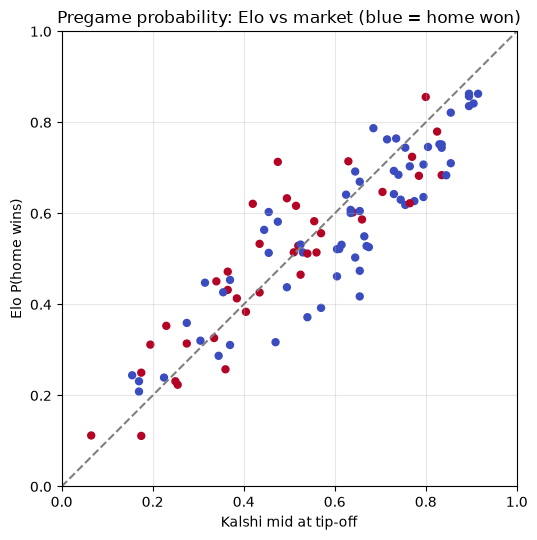

correlation 0.90, mean |Elo - Kalshi| 0.080


In [9]:
pregame = {
    "Elo": bc.log_loss_rows(games["home_won"].to_numpy(), games["prior_elo"].to_numpy()),
    "Kalshi tip-off": bc.log_loss_rows(games["home_won"].to_numpy(), games["prior_tipoff"].to_numpy()),
}
pregame["Elo - Kalshi"] = pregame["Elo"] - pregame["Kalshi tip-off"]
for name, losses in pregame.items():
    print(f"{name:<15} log loss {losses.mean():+.4f}  ±{1.96 * losses.std(ddof=1) / np.sqrt(len(losses)):.4f}")

cp.pregame(df)
plt.show()
print(f"correlation {games['prior_elo'].corr(games['prior_tipoff']):.2f}, "
      f"mean |Elo - Kalshi| {(games['prior_elo'] - games['prior_tipoff']).abs().mean():.3f}")

## 6. Example games

Six games picked at random from the sample, to put pictures behind the averages.

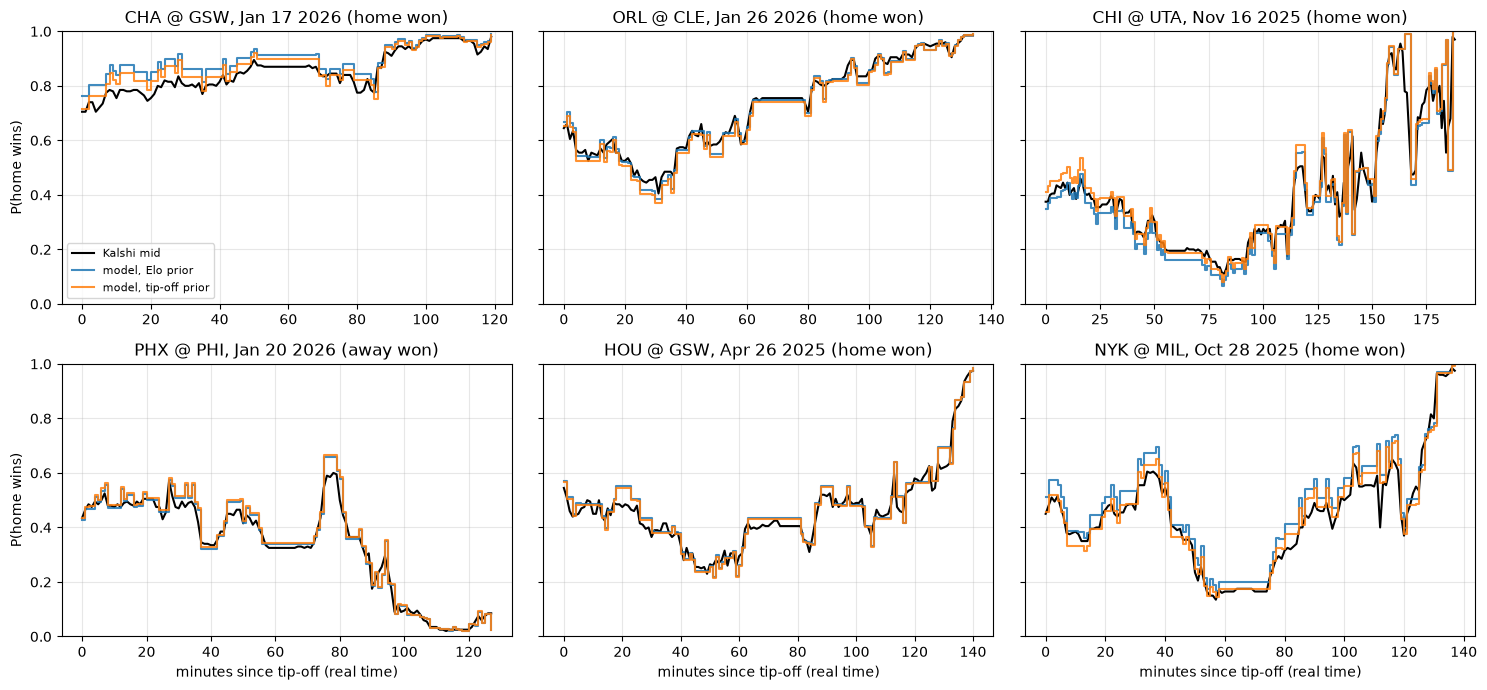

In [10]:
cp.example_games(df)
plt.show()

## Conclusions

**1. Given the same starting point, the model and the market predict about equally well.**
With the tip-off prior the model's log loss is 0.007 lower than the market's (±0.008),
so there is no clear edge over 100 games. Q4 is the only quarter whose interval excludes
zero (-0.011, ±0.010), but with five quarters tested one borderline result is expected
by chance. It is a lead to follow, not a finding.

**2. Calibration can't separate them at this sample size.** All three curves sit above
the diagonal by similar amounts because home teams won 62% of these games, while the
market's average tip-off price was 56.5%. That is luck in this sample shared by every
predictor, not a flaw in any one of them, and the ±95% bars overlap everywhere.

**3. The model is more extreme than the market, confirmed beyond Game 6.** Bucketed by the
market's own probability, the tip-off model sits 1-1.5 cents *below* the market when the
home team is behind and 1-1.7 cents *above* when it is ahead, with intervals clear of
zero at both ends. The typical disagreement is 2.3-3 cents per minute.

**4. The market acts as if σ ≈ 22, not 19.64,** and the results in this sample agree (best
σ for log loss: 22.5). The log-loss curve is flat between about 19 and 27, so 100 games
can't pin σ down. But both point the same way, and 22 is above every single-season fit
for 2015-23 (17.9-20.3). Either 2025-26 games swing more, or our σ is a little low for
the Kalshi era. The market's implied σ is highest in Q1 (26): it moves least on
early leads.

**5. The Elo prior is the weakest piece.** The model with Elo is 2 cents worse than the
market (±2.8) and is furthest away in Q1 (8 cents on average), with the gap shrinking as
the score takes over. Before tip-off, Kalshi's price beats Elo by 0.038 log loss
(±0.041), correlation 0.90, about 8 cents apart on average.

### What this means for the quoting rule

- **Start from the market's pregame price, not Elo.** Elo adds error that the market
  doesn't have.
- **Use σ ≈ 22 for the Kalshi era,** or blend toward the market. A σ of 19.64 makes our
  quotes too extreme by 1-2 cents at the tails, which is exactly where a faster trader
  would pick us off.
- **Spread floor of about 3 cents.** That is the typical model-market disagreement. It
  widens with `stern.p_volatility` late in close games.

### Next checks

- **Run every eligible game** (`uv run python src/batch_compare.py --n 803`, a few minutes).
  The intervals shrink by about 2.8 times, enough to settle the Q4 edge and the σ question.
- **Fit σ on 2025-26 results directly** to see whether this season really swings more.
- **Lead-lag:** does the market move before our play timestamps? Not tested here.